## **COVID-19 Lung CT Scan Classification**
In this project, I train an image classification model to classify individual lung CT images as COVID-19 or non-COVID-19.

I use transfer learning with **EfficientNetV2B0** pretrained on ImageNet. First, I train a new classifier while keeping the pretrained backbone frozen. Then, I unfreeze the backbone and fine-tune the model on my training dataset.

The model classifies individual CT images and is not intended for clinical diagnosis.

Dataset: [COVID-19 Lung CT Scans on Kaggle](https://www.kaggle.com/datasets/mehradaria/covid19-lung-ct-scans)

## Library

Import the libraries needed for data processing, training, and evaluation.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

tf.get_logger().setLevel("ERROR")

## Configuration

This section defines how the model learns.

If `model.h5` exists, I load it and skip training. Set `retrain = True` to train a new model and replace the saved results.


In [2]:
retrain       = False
seed          = 123
data_dir      = Path("ct_scans_dataset")
output_dir    = Path("outputs")
class_names   = ["non_covid", "covid"]

image_size    = (224, 224)
batch_size    = 16
warm_epochs   = 2
fine_epochs   = 23
warm_lr       = 1e-3
learning_rate = 6.00e-5
weight_decay  = 1.00e-5
dropout       = 0.4
rotation      = 0.03
horizontal_flip = True
patience      = 5
threshold     = 0.5
valid_size    = 0.15
test_size     = 0.15

output_dir.mkdir(parents=True, exist_ok=True)
keras.utils.set_random_seed(seed)
model_file = output_dir / "model.h5"
train_model = retrain or not model_file.exists()


In [3]:
gpus = tf.config.list_physical_devices("GPU")
assert gpus, "Pilih kernel .venv-tf dengan GPU."
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
print("GPU:", gpus)

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Data
Load the images and split them into training, validation, and test sets. Since the classes are imbalanced, I apply class weights during training and use macro-F1 as the main evaluation metric.

In [4]:
data = pd.DataFrame([
    {"path": p.relative_to(data_dir).as_posix(), "label": label}
    for label, name in enumerate(class_names)
    for p in sorted((data_dir / name).glob("*.png"))
])
assert set(data["label"]) == {0, 1}, "Periksa folder dataset."

split_file = output_dir / "split.csv"
if split_file.exists():
    saved = pd.read_csv(split_file)
    assert not saved["path"].duplicated().any()
    assert set(map(tuple, saved[["path", "label"]].values)) == set(map(tuple, data.values)), "Dataset berubah; periksa split.csv."
    assert set(saved["split"]) == {"train", "valid", "test"}
    data = saved
else:
    train, rest = train_test_split(
        data, test_size=valid_size + test_size, stratify=data["label"], random_state=seed
    )
    valid, test = train_test_split(
        rest, test_size=test_size / (valid_size + test_size), stratify=rest["label"], random_state=seed
    )
    data = pd.concat([
        train.assign(split="train"),
        valid.assign(split="valid"),
        test.assign(split="test"),
    ], ignore_index=True)
    data.to_csv(split_file, index=False)

train = data[data["split"] == "train"].reset_index(drop=True)
valid = data[data["split"] == "valid"].reset_index(drop=True)
test  = data[data["split"] == "test"].reset_index(drop=True)

weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=train["label"])
class_weight = dict(enumerate(weights.tolist()))
print(pd.crosstab(data["split"], data["label"]).rename(columns=dict(enumerate(class_names))))
print("Class weight:", class_weight)

label  non_covid  covid
split                  
test         142   1124
train        661   5246
valid        141   1125
Class weight: {0: 4.468229954614221, 1: 0.5630003812428517}


In [5]:
def read_image(path, label):
    image = tf.io.decode_png(tf.io.read_file(path), channels=3)
    image = tf.image.resize(image, image_size)
    return image, tf.cast(label, tf.float32)


def make_dataset(frame, training=False):
    paths = [str(data_dir / p) for p in frame["path"]]
    ds = tf.data.Dataset.from_tensor_slices((paths, frame["label"].to_numpy()))
    if training:
        ds = ds.shuffle(len(frame), seed=seed)
    ds = ds.map(read_image, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset(train, training=True)
valid_ds = make_dataset(valid)
y_valid  = valid["label"].to_numpy()

## Model
EfficientNetV2B0 pretrained on ImageNet and add data augmentation, dropout, and a binary classifier.

In [6]:
if train_model:
    base = keras.applications.EfficientNetV2B0(
        weights="imagenet",
        include_top=False,
        include_preprocessing=True,
        input_shape=(*image_size, 3),
        pooling="avg",
    )
    base.trainable = False

    inputs = keras.Input(shape=(*image_size, 3))
    x = inputs
    if horizontal_flip:
        x = keras.layers.RandomFlip("horizontal", seed=seed)(x)
    x = keras.layers.RandomRotation(rotation, seed=seed)(x)
    x = base(x, training=False)
    x = keras.layers.Dropout(dropout)(x)
    outputs = keras.layers.Dense(1, activation="sigmoid")(x)
    model = keras.Model(inputs, outputs)
else:
    model = keras.models.load_model(model_file, compile=False)
    print("Loaded:", model_file)


Loaded: outputs\model.h5


## Warm-up
Train the new classifier while keeping the pretrained backbone frozen.

In [10]:
if train_model:
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=warm_lr),
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    model.fit(
        train_ds,
        epochs=warm_epochs,
        class_weight=class_weight,
        verbose=1,
    )

## Fine-tuning
Unfreeze the backbone and fine-tune the model using AdamW to minimize binary cross-entropy loss. I save the weights with the highest validation macro-F1. Training stops after five consecutive epochs without improvement.

In [11]:
if train_model:
    class ValidationF1(keras.callbacks.Callback):
        def on_epoch_end(self, epoch, logs=None):
            probs = self.model.predict(valid_ds, verbose=0).ravel()
            logs["val_macro_f1"] = f1_score(
                y_valid, probs >= threshold, average="macro", zero_division=0
            )


    base.trainable = True
    model.compile(
        optimizer=keras.optimizers.experimental.AdamW(
            learning_rate=learning_rate,
            weight_decay=weight_decay,
            jit_compile=False,
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    weights_file = output_dir / "best.weights.h5"
    history = model.fit(
        train_ds,
        validation_data=valid_ds,
        epochs=fine_epochs,
        class_weight=class_weight,
        callbacks=[
            ValidationF1(),
            keras.callbacks.ModelCheckpoint(
                str(weights_file), monitor="val_macro_f1", mode="max",
                save_best_only=True, save_weights_only=True,
            ),
            keras.callbacks.EarlyStopping(
                monitor="val_macro_f1", mode="max", patience=patience,
            ),
        ],
        verbose=1,
    )

## Save model
Restore and save the best weights, along with the configuration and training history.

In [7]:
if train_model:
    model.load_weights(weights_file)
    model.save(output_dir / "model.h5", include_optimizer=False)
    pd.DataFrame(history.history).to_csv(output_dir / "history.csv", index=False)
    pd.DataFrame(history.history)[["loss", "val_loss"]].plot(xlabel="Epoch", ylabel="Loss")
    plt.show()

    config = {
        "model": "EfficientNetV2B0",
        "seed": seed,
        "class_names": class_names,
        "image_size": image_size,
        "batch_size": batch_size,
        "warm_epochs": warm_epochs,
        "fine_epochs": fine_epochs,
        "warm_lr": warm_lr,
        "learning_rate": learning_rate,
        "weight_decay": weight_decay,
        "dropout": dropout,
        "rotation": rotation,
        "horizontal_flip": horizontal_flip,
        "patience": patience,
        "threshold": threshold,
        "valid_size": valid_size,
        "test_size": test_size,
        "split": "split.csv",
        "class_weight": class_weight,
        "validation_macro_f1": max(history.history["val_macro_f1"]),
    }
    (output_dir / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")

## Test
Evaluate the selected model on the completely unseen set using accuracy, macro-F1, precision, recall, and a confusion matrix. I do not use the test results to tune hyperparameters.

Accuracy: 0.9968404423380727
Macro-F1: 0.9921642899584076
              precision    recall  f1-score   support

   non_covid     0.9726    1.0000    0.9861       142
       covid     1.0000    0.9964    0.9982      1124

    accuracy                         0.9968      1266
   macro avg     0.9863    0.9982    0.9922      1266
weighted avg     0.9969    0.9968    0.9969      1266



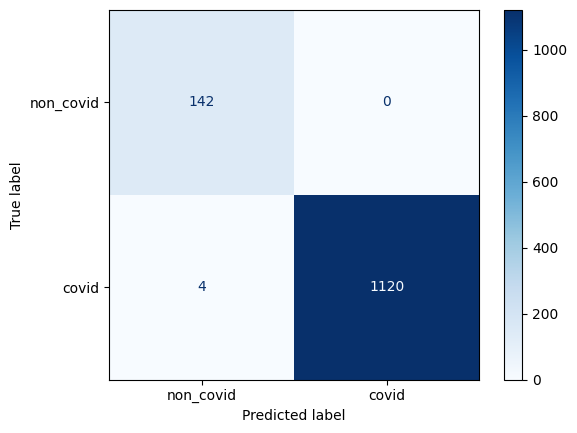

605

In [8]:
test_ds = make_dataset(test)
y_test  = test["label"].to_numpy()
probs   = model.predict(test_ds, verbose=0).ravel()
pred    = (probs >= threshold).astype(int)

print("Accuracy:", accuracy_score(y_test, pred))
print("Macro-F1:", f1_score(y_test, pred, average="macro", zero_division=0))
print(classification_report(
    y_test, pred, labels=[0, 1], target_names=class_names, digits=4, zero_division=0
))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, labels=[0, 1], display_labels=class_names, cmap="Blues"
)
plt.show()

test.assign(prob_covid=probs, prediction=pred).to_csv(
    output_dir / "test_predictions.csv", index=False
)
report = classification_report(
    y_test, pred, labels=[0, 1], target_names=class_names,
    output_dict=True, zero_division=0,
)
(output_dir / "test_metrics.json").write_text(json.dumps(report, indent=2), encoding="utf-8")

## Prediksi satu gambar
Load the saved model to predict whether a CT image belongs to the COVID-19 or non-COVID-19 class.

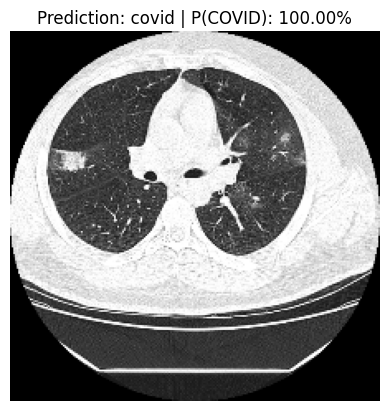

File: ct_scans_dataset\covid\COVID-19_2745.png
Prediksi: covid
Probabilitas covid: 1.0


In [9]:
image_path = data_dir / test.sample(1).iloc[0]["path"]
model = keras.models.load_model(output_dir / "model.h5", compile=False)

image, _ = read_image(str(image_path), 0)
prob = float(model.predict(image[None, ...], verbose=0)[0, 0])
prediction = class_names[int(prob >= threshold)]

plt.imshow(image.numpy().astype("uint8"))
plt.title(f"Prediction: {prediction} | P(COVID): {prob:.2%}")
plt.axis("off")
plt.show()

print("File:", image_path)
print("Prediksi:", prediction)
print("Probabilitas covid:", round(prob, 4))